# SWYNEX — Task 3: Modeling and Evaluation
## Predicting Adult Census Income (Baseline Classification)

**Goal:** Train and evaluate a baseline machine-learning model that predicts whether a person's annual income is `>50K` using demographic and employment-related census attributes.

**Dataset:** UCI Adult / Census Income dataset. This notebook downloads the public dataset when run. No personal data is collected by this project.

**Workflow:** load data → clean missing/unknown values → split data → preprocess numeric/categorical columns → train a baseline logistic-regression model → evaluate with appropriate metrics → discuss limitations.

> This is an educational baseline, not a tool for making real-world decisions about individuals. The dataset contains sensitive demographic attributes and historical/social biases.

## 1. Install / import libraries

If running locally, install packages from `requirements.txt` first. In Google Colab, run the next cell if any import is missing.

In [10]:
# If needed, uncomment and run:
# %pip install -r requirements.txt

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)
from sklearn.dummy import DummyClassifier
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the public UCI Adult dataset

The training file is `adult.data`; the held-out official test file is `adult.test`. We combine them and create our own stratified train/test split so the evaluation workflow is easy to reproduce. The UCI test file includes a trailing period after the positive class label; the cleaning step removes it.

In [11]:
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]
BASE_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"

train_url = BASE_URL + "adult.data"
test_url = BASE_URL + "adult.test"

train_raw = pd.read_csv(
    train_url, header=None, names=COLUMNS, na_values="?", skipinitialspace=True,
    comment="|"
)
test_raw = pd.read_csv(
    test_url, header=None, names=COLUMNS, na_values="?", skipinitialspace=True,
    comment="|", skiprows=1
)
df = pd.concat([train_raw, test_raw], ignore_index=True)

# Normalize text values and target labels
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df["income"] = df["income"].str.replace(".", "", regex=False)
df = df.dropna(subset=["income"]).reset_index(drop=True)

print("Dataset shape:", df.shape)
display(df.head())
display(df["income"].value_counts(dropna=False))

Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


income
<=50K    37155
>50K     11687
Name: count, dtype: int64

## 3. Quick data-quality checks

Unknown values are represented as missing values (`NaN`). We inspect missingness and duplicates, then remove exact duplicate rows for this baseline. The model pipeline imputes missing numeric and categorical feature values using training data only.

In [12]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "dtype": df.dtypes.astype(str)
})
display(quality.sort_values("missing_count", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after duplicate removal:", df.shape)

print("\nTarget distribution:")
display(df["income"].value_counts(normalize=True).mul(100).round(2).rename("percent"))

,missing_count,missing_percent,dtype
occupation,2809,5.75,str
workclass,2799,5.73,str
native_country,857,1.75,str
fnlwgt,0,0.00,int64
education,0,0.00,str
education_num,0,0.00,int64
age,0,0.00,int64
marital_status,0,0.00,str
relationship,0,0.00,str
sex,0,0.00,str


Exact duplicate rows: 52
Shape after duplicate removal: (48790, 15)

Target distribution:


income
<=50K    76.06
>50K     23.94
Name: percent, dtype: float64

## 4. Define target and split the data

The target is binary: `1` means income `>50K`, and `0` means income `<=50K`. We exclude the target from the features and use a stratified split to preserve the class ratio in both sets.

In [13]:
TARGET = "income"
X = df.drop(columns=[TARGET]).copy()
y = (df[TARGET] == ">50K").astype(int)

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 39032
Test rows: 9758
Numeric features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']
Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']


## 5. Build preprocessing and baseline models

Numeric columns use median imputation and standardization. Categorical columns use most-frequent imputation and one-hot encoding. All preprocessing is inside a scikit-learn `Pipeline`, which helps prevent data leakage.

We compare logistic regression with a simple majority-class dummy baseline.

In [14]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])
baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(X_train, y_train)
model.fit(X_train, y_train)
print("Both baseline models trained successfully.")

Both baseline models trained successfully.


## 6. Evaluate the model

We report accuracy, precision, recall, F1-score, and ROC-AUC. Because the classes are imbalanced, accuracy alone can be misleading; F1, recall, precision, and ROC-AUC provide additional perspectives. `class_weight="balanced"` is used to make the model pay more attention to the minority class.

In [15]:
def evaluate_model(name, fitted_model, X_eval, y_eval):
    pred = fitted_model.predict(X_eval)
    row = {
        "model": name,
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred, zero_division=0),
        "recall": recall_score(y_eval, pred, zero_division=0),
        "f1": f1_score(y_eval, pred, zero_division=0),
    }
    if hasattr(fitted_model, "predict_proba"):
        row["roc_auc"] = roc_auc_score(y_eval, fitted_model.predict_proba(X_eval)[:, 1])
    else:
        row["roc_auc"] = np.nan
    return row

results = pd.DataFrame([
    evaluate_model("Majority-class dummy", baseline, X_test, y_test),
    evaluate_model("Logistic regression", model, X_test, y_test)
]).set_index("model")
display(results.round(4))

print("Classification report — Logistic Regression")
print(classification_report(
    y_test, model.predict(X_test),
    target_names=["<=50K", ">50K"], zero_division=0
))

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Majority-class dummy,0.7606,0.000,0.0000,0.0000,0.500
Logistic regression,0.8082,0.566,0.8519,0.6801,0.908


Classification report — Logistic Regression
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86      7422
        >50K       0.57      0.85      0.68      2336

    accuracy                           0.81      9758
   macro avg       0.76      0.82      0.77      9758
weighted avg       0.85      0.81      0.82      9758



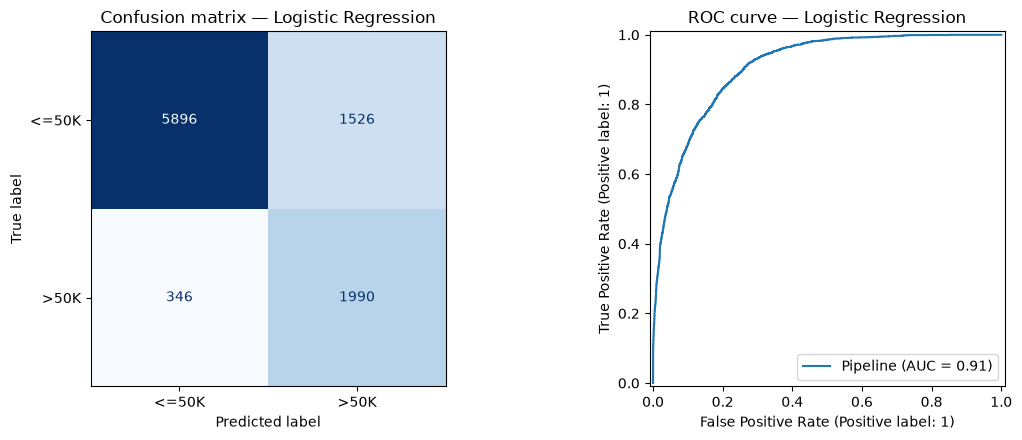

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(
    model, X_test, y_test, display_labels=["<=50K", ">50K"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion matrix — Logistic Regression")
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=axes[1])
axes[1].set_title("ROC curve — Logistic Regression")
plt.tight_layout()
plt.show()

## 7. Inspect the strongest model coefficients

Coefficients are shown as a model diagnostic, not as causal explanations. Positive coefficients increase the model's estimated log-odds of predicting `>50K`; negative coefficients decrease them, holding other encoded features constant. Correlated features and dataset biases can make coefficients difficult to interpret.

In [17]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
coef_table = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_table["abs_coefficient"] = coef_table["coefficient"].abs()
display(coef_table.sort_values("abs_coefficient", ascending=False).head(20).drop(columns="abs_coefficient"))

,feature,coefficient
3,numeric__capital_gain,2.296848
31,categorical__marital_status_Married-AF-spouse,1.664370
32,categorical__marital_status_Married-civ-spouse,1.530319
84,categorical__native_country_Ireland,1.434193
45,categorical__occupation_Priv-house-serv,-1.384214
95,categorical__native_country_Portugal,1.298513
67,categorical__native_country_Columbia,-1.230271
34,categorical__marital_status_Never-married,-1.148687
41,categorical__occupation_Farming-fishing,-0.942567
56,categorical__relationship_Wife,0.908676


## 8. Save the model and evaluation results

The following cell creates a `models/` file and a `reports/` CSV. Commit the notebook and code to GitHub; do not commit large generated data files unless your task instructions specifically require them.

In [18]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)
Path("reports").mkdir(exist_ok=True)

joblib.dump(model, "models/adult_income_logistic_regression.joblib")
results.to_csv("reports/model_evaluation_metrics.csv")
coef_table.sort_values("abs_coefficient", ascending=False).to_csv(
    "reports/model_coefficients.csv", index=False
)
print("Saved model to models/adult_income_logistic_regression.joblib")
print("Saved metrics to reports/model_evaluation_metrics.csv")
print("Saved coefficients to reports/model_coefficients.csv")

Saved model to models/adult_income_logistic_regression.joblib
Saved metrics to reports/model_evaluation_metrics.csv
Saved coefficients to reports/model_coefficients.csv


## 9. Limitations and conclusion

### What this baseline demonstrates
- A reproducible classification pipeline for a public dataset.
- Separate preprocessing and modeling steps inside a pipeline.
- Evaluation against a naive majority-class baseline.
- Multiple evaluation metrics and visual diagnostics.

### Limitations
- The dataset is historical and may reflect social and sampling biases.
- Income is a sensitive socioeconomic label; model predictions should not be used to make decisions about individuals.
- Accuracy and other metrics can vary across demographic groups. This notebook does not constitute a fairness audit.
- Logistic regression is a simple baseline and may not capture nonlinear relationships.
- A random split is useful for a class project but does not prove performance on current populations.
- Coefficients are associations within this model, not causal effects.

### Final conclusion
Use the actual metric values displayed in Section 6 when writing your conclusion. Do not claim a particular accuracy before running the notebook. A good conclusion compares logistic regression with the dummy baseline, discusses precision/recall trade-offs, and notes the dataset's limitations.